# Lab Assignment: Implementation of RNN-Based Text Classification
**Course:** Artificial Neural Networks and Deep Learning  |  **Lab:** Recurrent Neural Network (RNN) Classifier

## Aim
To implement a Recurrent Neural Network (SimpleRNN) with TensorFlow/Keras for **binary sentiment classification** of IMDB movie reviews (Positive = 1, Negative = 0) and evaluate its performance.

- All experiments use the same seed (`SEED = 42`), the same data split (`validation_split = 0.2`) and the same test set, so comparisons are fair.

## Assumptions
- Architecture: `Input -> Embedding(10000, 128) -> SimpleRNN(units) -> Dense(1, sigmoid)`. The final `Dense(1, sigmoid)` layer is the "Dense -> Output" layer of the brief.
- "Training accuracy" in the tables is the running training accuracy of the **last epoch** (as reported by Keras); Task 5 additionally re-evaluates the final model on the whole training set.
- The configuration *64 units / 5 epochs / batch 64* is shared by experiments A2, B2 and C2, so it is trained once and reused (identical configuration, identical seed).

---
## 0. Setup

In [1]:
# ---- Imports ----
import time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from IPython.display import display, Markdown

# ---- Global settings required by the assignment ----
VOCAB_SIZE = 10000   # keep only the 10,000 most frequent words
MAX_LEN    = 200     # every review is padded / truncated to exactly 200 tokens
EMBED_DIM  = 128     # size of each word-embedding vector
SEED       = 42      # fixed seed -> reproducible, comparable experiments

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU available     :", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available     : True


---
## Task 1 - Load and Explore the Dataset

The IMDB dataset (50,000 labelled reviews, split 25,000 train / 25,000 test) is loaded with `tensorflow.keras.datasets.imdb`. With `num_words=10000`, only the 10,000 most frequent words keep their own index; every rarer word is replaced by the "unknown" index `2`. Reviews are already converted into lists of integer word indices.

In [2]:
# ---- Load the IMDB dataset (vocabulary limited to the 10,000 most frequent words) ----
(x_train_raw, y_train), (x_test_raw, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Number of training samples :", len(x_train_raw))
print("Number of testing samples  :", len(x_test_raw))
print("Shape of training data (raw):", x_train_raw.shape, "-> one variable-length list of word indices per review")
print("Shape of testing data  (raw):", x_test_raw.shape)
print("Shape of training labels    :", y_train.shape)
print("Shape of testing labels     :", y_test.shape)

# ---- Class balance: number of positive (1) and negative (0) reviews ----
for name, labels in [("Training", y_train), ("Testing ", y_test)]:
    neg, pos = np.bincount(labels)
    print(f"{name}: Positive (1) = {pos:,} | Negative (0) = {neg:,}")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of training samples : 25000
Number of testing samples  : 25000
Shape of training data (raw): (25000,) -> one variable-length list of word indices per review
Shape of testing data  (raw): (25000,)
Shape of training labels    : (25000,)
Shape of testing labels     : (25000,)
Training: Positive (1) = 12,500 | Negative (0) = 12,500
Testing : Positive (1) = 12,500 | Negative (0) = 12,500


Review length (tokens): min=11, mean=239, median=178, max=2494
Share of training reviews longer than 200 tokens (will be truncated): 42.7%


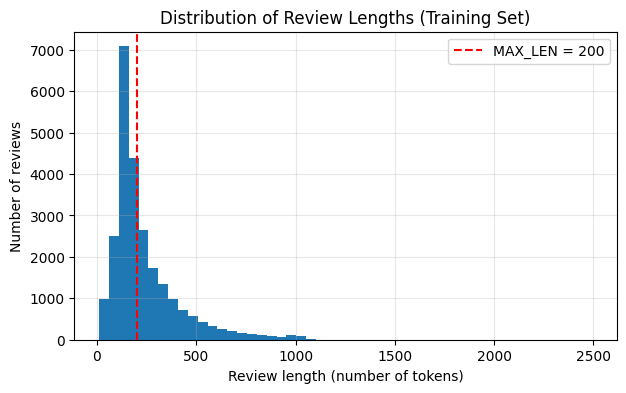

In [3]:
# ---- Review length statistics (this justifies the choice of MAX_LEN = 200) ----
lengths = np.array([len(review) for review in x_train_raw])
print(f"Review length (tokens): min={lengths.min()}, mean={lengths.mean():.0f}, "
      f"median={np.median(lengths):.0f}, max={lengths.max()}")
print(f"Share of training reviews longer than {MAX_LEN} tokens (will be truncated): {(lengths > MAX_LEN).mean():.1%}")

plt.figure(figsize=(7, 4))
plt.hist(lengths, bins=50)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Distribution of Review Lengths (Training Set)")
plt.xlabel("Review length (number of tokens)")
plt.ylabel("Number of reviews")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
# ---- Decode one review back to words to see what the model actually receives ----
word_index = imdb.get_word_index()                              # word -> index
index_to_word = {idx + 3: w for w, idx in word_index.items()}   # Keras shifts real words by +3
index_to_word.update({0: "<PAD>", 1: "<START>", 2: "<UNK>", 3: "<UNUSED>"})

def decode_review(sequence):
    return " ".join(index_to_word.get(i, "?") for i in sequence)

print("Label of review 0:", y_train[0], "(1 = Positive, 0 = Negative)")
print("Raw integer sequence (first 15):", x_train_raw[0][:15])
print("Decoded text:", decode_review(x_train_raw[0])[:350], "...")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Label of review 0: 1 (1 = Positive, 0 = Negative)
Raw integer sequence (first 15): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4]
Decoded text: <START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film t ...


---
## Task 2 - Data Preprocessing

Steps: (1) load the data - done above; (2) limit the vocabulary to the 10,000 most frequent words - done by `num_words=10000`; (3) reviews are already numeric sequences; (4) **pad / truncate every review to length 200** with `pad_sequences`.

**Padding choice:** Keras' defaults are `padding="pre"` and `truncating="pre"`, i.e. zeros are added at the *start* and, for long reviews, the *beginning* is cut. This is deliberate and recommended for RNNs: a recurrent network reads left to right, so with pre-padding the **real words are the last things it reads**, right before the final hidden state is passed to the output layer. With post-padding the network would end by processing dozens of meaningless zeros and would largely "forget" the review.

In [5]:
# ---- Pad / truncate all reviews to exactly MAX_LEN tokens ----
x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN)   # defaults: padding="pre", truncating="pre"
x_test  = pad_sequences(x_test_raw,  maxlen=MAX_LEN)

print("Final training data shape:", x_train.shape)
print("Final testing data shape :", x_test.shape)
print("Data type                :", x_train.dtype)
assert x_train.shape[1] == MAX_LEN and x_test.shape[1] == MAX_LEN, "all reviews must have length 200"
print("Largest word index in data:", x_train.max(), f"(must be < VOCAB_SIZE = {VOCAB_SIZE})")

# ---- Show padding in action on the shortest review ----
shortest = int(np.argmin(lengths))
print(f"\nShortest review has {lengths[shortest]} tokens; after padding its first 20 values are:")
print(x_train[shortest][:20], "<- zeros are padding")

Final training data shape: (25000, 200)
Final testing data shape : (25000, 200)
Data type                : int32
Largest word index in data: 9999 (must be < VOCAB_SIZE = 10000)

Shortest review has 11 tokens; after padding its first 20 values are:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0] <- zeros are padding


---
## Task 3 - Build the RNN Classifier

**Architecture:** `Input (200,) -> Embedding(10000, 128) -> SimpleRNN(64) -> Dense(1, sigmoid)`

| Layer | Purpose | Parameters |
|---|---|---|
| Embedding | turns each of the 200 word indices into a learned 128-dimensional vector | 10,000 x 128 = 1,280,000 |
| SimpleRNN(64) | reads the 200 vectors one after another and keeps a 64-dimensional hidden state (the network's memory) | 64 x (128 + 64 + 1) = 12,352 |
| Dense(1, sigmoid) | converts the final hidden state into P(review is positive) | 64 + 1 = 65 |

`build_rnn()` is a reusable function so that the hyper-parameter experiments can change only the settings they study.

In [6]:
def build_rnn(units=64, two_layer=False):
    """Embedding -> SimpleRNN (-> SimpleRNN) -> Dense(sigmoid).
    two_layer=True is used only in the Task 9 challenge."""
    stack = [layers.Input(shape=(MAX_LEN,)),
             layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM)]
    if two_layer:
        # the first recurrent layer must hand a vector for EVERY time step to the second one
        stack += [layers.SimpleRNN(units, return_sequences=True),
                  layers.SimpleRNN(units)]
    else:
        stack += [layers.SimpleRNN(units)]
    stack += [layers.Dense(1, activation="sigmoid")]   # sigmoid -> probability of "Positive"
    return models.Sequential(stack)

tf.keras.utils.set_random_seed(SEED)
baseline_model = build_rnn(units=64)
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

---
## Task 4 - Compile and Train the Model

Settings required by the brief: optimizer **Adam**, loss **binary cross-entropy**, metric **accuracy**, **5 epochs**, **batch size 64**, **validation split 20 %**.

Note: `validation_split` takes the *last* 20 % of the training arrays (before shuffling). The Keras IMDB arrays are stored in shuffled order, so this validation set should be balanced - verified in the next cell.

In [7]:
# ---- Check the validation portion is class-balanced ----
n_val = int(len(x_train) * 0.2)
val_neg, val_pos = np.bincount(y_train[-n_val:])
print(f"Validation split: {n_val:,} reviews -> Positive = {val_pos:,}, Negative = {val_neg:,}")

# ---- Compile ----
baseline_model.compile(optimizer="adam",
                       loss="binary_crossentropy",
                       metrics=["accuracy"])

# ---- Train (baseline: 64 units, 5 epochs, batch size 64, 20% validation) ----
start = time.time()
history = baseline_model.fit(x_train, y_train,
                             epochs=5,
                             batch_size=64,
                             validation_split=0.2,
                             verbose=2)
baseline_time = time.time() - start
print(f"\nTraining time: {baseline_time:.0f} s")

Validation split: 5,000 reviews -> Positive = 2,469, Negative = 2,531
Epoch 1/5
313/313 - 11s - 35ms/step - accuracy: 0.6998 - loss: 0.5586 - val_accuracy: 0.8102 - val_loss: 0.4288
Epoch 2/5
313/313 - 6s - 20ms/step - accuracy: 0.8608 - loss: 0.3307 - val_accuracy: 0.8180 - val_loss: 0.4249
Epoch 3/5
313/313 - 5s - 17ms/step - accuracy: 0.9100 - loss: 0.2252 - val_accuracy: 0.7084 - val_loss: 0.6569
Epoch 4/5
313/313 - 5s - 17ms/step - accuracy: 0.9664 - loss: 0.0969 - val_accuracy: 0.7358 - val_loss: 0.7356
Epoch 5/5
313/313 - 5s - 17ms/step - accuracy: 0.9861 - loss: 0.0458 - val_accuracy: 0.7156 - val_loss: 0.8958

Training time: 33 s


In [8]:
# ---- Record training / validation accuracy and loss for every epoch ----
hist_df = pd.DataFrame(history.history)
hist_df.index = range(1, len(hist_df) + 1)
hist_df.index.name = "Epoch"
hist_df = hist_df.rename(columns={"accuracy": "Training Accuracy", "val_accuracy": "Validation Accuracy",
                                  "loss": "Training Loss", "val_loss": "Validation Loss"})
display(hist_df[["Training Accuracy", "Validation Accuracy", "Training Loss", "Validation Loss"]].round(4))

,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
Epoch,,,,
1,0.6998,0.8102,0.5586,0.4288
2,0.8608,0.8180,0.3307,0.4249
3,0.9100,0.7084,0.2252,0.6569
4,0.9664,0.7358,0.0969,0.7356
5,0.9861,0.7156,0.0458,0.8958


---
## Task 5 - Evaluate the Model

The model is evaluated on the 25,000 test reviews, which were **never used for training or validation**.

In [9]:
# ---- Test-set evaluation ----
test_loss, test_acc = baseline_model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}  ({test_acc:.2%})")

# ---- Re-evaluate the FINAL model on the whole training set (for a like-for-like comparison) ----
train_loss_eval, train_acc_eval = baseline_model.evaluate(x_train, y_train, verbose=0)
print(f"\nTraining accuracy of the final model (re-evaluated on all training data): {train_acc_eval:.4f}  ({train_acc_eval:.2%})")
print(f"Training accuracy reported during the last epoch                        : {history.history['accuracy'][-1]:.4f}")

Test loss    : 0.8679
Test accuracy: 0.7271  (72.71%)

Training accuracy of the final model (re-evaluated on all training data): 0.9331  (93.31%)
Training accuracy reported during the last epoch                        : 0.9861


In [10]:
# ---- Answers to Q1 and Q2 (generated from the actual results) ----
gap_pp = (train_acc_eval - test_acc) * 100

q1 = f"**Q1. Final test accuracy:** the SimpleRNN model reaches a test accuracy of **{test_acc:.2%}** (test loss {test_loss:.4f})."

if gap_pp > 0.5:
    q2 = (f"**Q2. Test vs. training accuracy:** the test accuracy ({test_acc:.2%}) is **lower** than the training accuracy "
          f"({train_acc_eval:.2%}), a gap of {gap_pp:.2f} percentage points. This is expected: the weights were optimised on the "
          "training reviews, so the model has partly adapted to them (including their noise), whereas test reviews are completely new. "
          "The size of this *generalisation gap* indicates how much the model overfits - "
          + ("a large gap means noticeable overfitting." if gap_pp > 5 else "here the gap is modest, so overfitting is limited after 5 epochs."))
else:
    q2 = (f"**Q2. Test vs. training accuracy:** the test accuracy ({test_acc:.2%}) is about the same as or higher than the training accuracy "
          f"({train_acc_eval:.2%}). This is unusual but possible: the running training accuracy reported by Keras is averaged over the epoch "
          "while the weights were still improving, a SimpleRNN is a low-capacity, noisy learner, and 5 epochs are too few to memorise the "
          "training set. It means the model is not overfitting at this point (if anything it is still under-trained).")

display(Markdown(q1))
display(Markdown(q2))

**Q1. Final test accuracy:** the SimpleRNN model reaches a test accuracy of **72.71%** (test loss 0.8679).

**Q2. Test vs. training accuracy:** the test accuracy (72.71%) is **lower** than the training accuracy (93.31%), a gap of 20.60 percentage points. This is expected: the weights were optimised on the training reviews, so the model has partly adapted to them (including their noise), whereas test reviews are completely new. The size of this *generalisation gap* indicates how much the model overfits - a large gap means noticeable overfitting.

---
## Task 6 - Performance Visualization

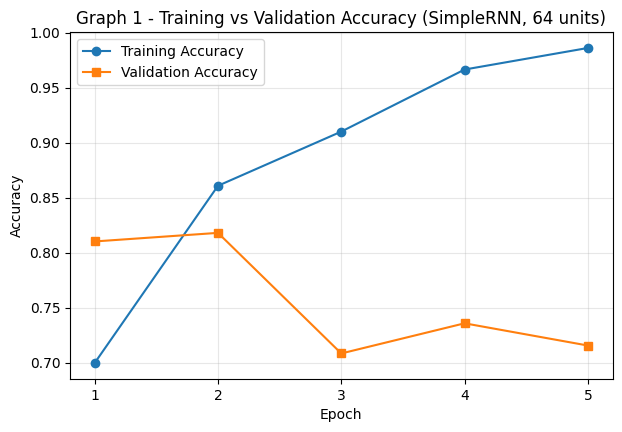

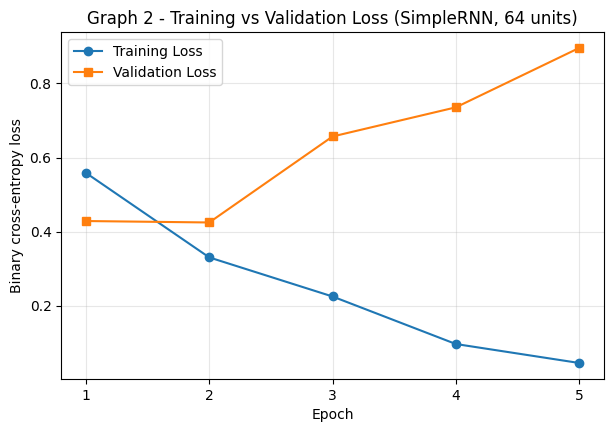

In [11]:
epochs_range = list(range(1, len(history.history["accuracy"]) + 1))

# ---- Graph 1: accuracy ----
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="s", label="Validation Accuracy")
plt.title("Graph 1 - Training vs Validation Accuracy (SimpleRNN, 64 units)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_range)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# ---- Graph 2: loss ----
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], marker="s", label="Validation Loss")
plt.title("Graph 2 - Training vs Validation Loss (SimpleRNN, 64 units)")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.xticks(epochs_range)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Interpretation of the graphs
The next cell reads the curves you just produced and describes them. Things to look for: (1) a **rising training accuracy / falling training loss** means the model is learning; (2) a **validation curve that follows the training curve** means it generalises; (3) a **validation loss that starts rising while training loss keeps falling** is the classic sign of overfitting; (4) **jagged curves** show unstable training, which is common for SimpleRNNs.

In [12]:
def interpret_curves(h):
    """Generate a plain-language reading of a Keras history dictionary."""
    tr_acc, va_acc = np.array(h["accuracy"]), np.array(h["val_accuracy"])
    tr_loss, va_loss = np.array(h["loss"]), np.array(h["val_loss"])
    n = len(tr_acc)
    best_ep = int(np.argmax(va_acc)) + 1
    min_loss_ep = int(np.argmin(va_loss)) + 1
    gap = (tr_acc[-1] - va_acc[-1]) * 100
    lines = []

    # Graph 1 (accuracy)
    lines.append(f"- **Graph 1 (accuracy):** training accuracy moved from {tr_acc[0]:.2%} (epoch 1) to {tr_acc[-1]:.2%} (epoch {n}); "
                 f"validation accuracy moved from {va_acc[0]:.2%} to {va_acc[-1]:.2%} and peaked at {va_acc.max():.2%} in epoch {best_ep}.")
    if gap > 5:
        lines.append(f"- The final training-validation gap is {gap:.1f} percentage points: the model fits the training data clearly better than unseen data, i.e. **overfitting** has started.")
    elif gap > 2:
        lines.append(f"- The final training-validation gap is {gap:.1f} percentage points: a **mild** overfitting tendency.")
    else:
        lines.append(f"- The final training-validation gap is only {gap:.1f} percentage points: the model **generalises well** at this stage and shows little overfitting.")
    if np.max(np.abs(np.diff(va_acc))) > 0.05:
        lines.append("- Validation accuracy changes by more than 5 points between some epochs: training is **unstable/noisy**, typical for a SimpleRNN whose gradients vanish or explode over 200 time steps.")

    # Graph 2 (loss)
    lines.append(f"- **Graph 2 (loss):** training loss fell from {tr_loss[0]:.3f} to {tr_loss[-1]:.3f}; validation loss reached its minimum ({va_loss.min():.3f}) at epoch {min_loss_ep} and ended at {va_loss[-1]:.3f}.")
    if min_loss_ep < n and va_loss[-1] > va_loss.min() + 0.02:
        lines.append(f"- Validation loss **rises after epoch {min_loss_ep}** while training loss keeps falling: the model starts to memorise the training reviews. Epoch {min_loss_ep} would be a sensible early-stopping point.")
    else:
        lines.append("- Validation loss did not rise noticeably above its minimum, so there is no clear overfitting in this loss curve; more epochs may still help.")
    display(Markdown("\n".join(lines)))

interpret_curves(history.history)

- **Graph 1 (accuracy):** training accuracy moved from 69.98% (epoch 1) to 98.61% (epoch 5); validation accuracy moved from 81.02% to 71.56% and peaked at 81.80% in epoch 2.
- The final training-validation gap is 27.0 percentage points: the model fits the training data clearly better than unseen data, i.e. **overfitting** has started.
- Validation accuracy changes by more than 5 points between some epochs: training is **unstable/noisy**, typical for a SimpleRNN whose gradients vanish or explode over 200 time steps.
- **Graph 2 (loss):** training loss fell from 0.559 to 0.046; validation loss reached its minimum (0.425) at epoch 2 and ended at 0.896.
- Validation loss **rises after epoch 2** while training loss keeps falling: the model starts to memorise the training reviews. Epoch 2 would be a sensible early-stopping point.

---
## Task 7 - Hyperparameter Experimentation

A helper function trains and evaluates one configuration, changing **only** the parameter under study (everything else - seed, optimizer, loss, validation split - is identical). It records training accuracy, validation accuracy, test accuracy, training time and parameter count.

In [13]:
def run_experiment(units=64, epochs=5, batch_size=64, two_layer=False):
    """Train one configuration from scratch and return its metrics."""
    tf.keras.utils.set_random_seed(SEED)                       # same starting point for every experiment
    model = build_rnn(units=units, two_layer=two_layer)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                  validation_split=0.2, verbose=0)
    train_time = time.time() - t0
    t_loss, t_acc = model.evaluate(x_test, y_test, verbose=0)
    return {"units": units, "epochs": epochs, "batch": batch_size,
            "train_acc": h.history["accuracy"][-1], "val_acc": h.history["val_accuracy"][-1],
            "test_acc": t_acc, "test_loss": t_loss, "time_s": train_time,
            "params": model.count_params(), "history": h.history}

# The baseline run from Task 4 (64 units / 5 epochs / batch 64) is shared by A2, B2 and C2
baseline_result = {"units": 64, "epochs": 5, "batch": 64,
                   "train_acc": history.history["accuracy"][-1], "val_acc": history.history["val_accuracy"][-1],
                   "test_acc": test_acc, "test_loss": test_loss, "time_s": baseline_time,
                   "params": baseline_model.count_params(), "history": history.history}

### Experiment A - Number of RNN units (32 / 64 / 128)

In [14]:
print("Running A1 (32 units)  ...")
res_A1 = run_experiment(units=32)
print(f"  done -> test accuracy {res_A1['test_acc']:.4f} ({res_A1['time_s']:.0f} s)")

res_A2 = baseline_result    # 64 units = the baseline

print("Running A3 (128 units) ...")
res_A3 = run_experiment(units=128)
print(f"  done -> test accuracy {res_A3['test_acc']:.4f} ({res_A3['time_s']:.0f} s)")

Running A1 (32 units)  ...
  done -> test accuracy 0.7709 (32 s)
Running A3 (128 units) ...
  done -> test accuracy 0.7985 (33 s)


### Experiment B - Number of epochs (3 / 5 / 10)

In [15]:
print("Running B1 (3 epochs)  ...")
res_B1 = run_experiment(epochs=3)
print(f"  done -> test accuracy {res_B1['test_acc']:.4f} ({res_B1['time_s']:.0f} s)")

res_B2 = baseline_result    # 5 epochs = the baseline

print("Running B3 (10 epochs) ...")
res_B3 = run_experiment(epochs=10)
print(f"  done -> test accuracy {res_B3['test_acc']:.4f} ({res_B3['time_s']:.0f} s)")

Running B1 (3 epochs)  ...
  done -> test accuracy 0.8186 (20 s)
Running B3 (10 epochs) ...
  done -> test accuracy 0.7646 (58 s)


### Experiment C - Batch size (32 / 64 / 128)

In [16]:
print("Running C1 (batch 32)  ...")
res_C1 = run_experiment(batch_size=32)
print(f"  done -> test accuracy {res_C1['test_acc']:.4f} ({res_C1['time_s']:.0f} s)")

res_C2 = baseline_result    # batch 64 = the baseline

print("Running C3 (batch 128) ...")
res_C3 = run_experiment(batch_size=128)
print(f"  done -> test accuracy {res_C3['test_acc']:.4f} ({res_C3['time_s']:.0f} s)")

Running C1 (batch 32)  ...
  done -> test accuracy 0.6209 (56 s)
Running C3 (batch 128) ...
  done -> test accuracy 0.7758 (19 s)


### Results table (required format) with training time and parameter count added

In [17]:
experiment_table = [("A1", "RNN = 32",     res_A1), ("A2", "RNN = 64",     res_A2), ("A3", "RNN = 128",    res_A3),
                    ("B1", "Epochs = 3",   res_B1), ("B2", "Epochs = 5",   res_B2), ("B3", "Epochs = 10",  res_B3),
                    ("C1", "Batch = 32",   res_C1), ("C2", "Batch = 64",   res_C2), ("C3", "Batch = 128",  res_C3)]

results_df = pd.DataFrame([{"Experiment": e, "Parameter": p,
                            "Training Accuracy": r["train_acc"], "Validation Accuracy": r["val_acc"],
                            "Test Accuracy": r["test_acc"], "Training Time (s)": r["time_s"],
                            "Trainable Parameters": r["params"]} for e, p, r in experiment_table])

shown = results_df.copy()
for col in ["Training Accuracy", "Validation Accuracy", "Test Accuracy"]:
    shown[col] = shown[col].map(lambda v: f"{v:.2%}")
shown["Training Time (s)"] = shown["Training Time (s)"].map(lambda v: f"{v:.0f}")
shown["Trainable Parameters"] = shown["Trainable Parameters"].map(lambda v: f"{v:,}")
display(shown)

,Experiment,Parameter,Training Accuracy,Validation Accuracy,Test Accuracy,Training Time (s),Trainable Parameters
0,A1,RNN = 32,98.91%,76.34%,77.09%,32,"1,285,185"
1,A2,RNN = 64,98.61%,71.56%,72.71%,33,"1,292,417"
2,A3,RNN = 128,89.25%,79.50%,79.85%,33,"1,313,025"
3,B1,Epochs = 3,91.62%,82.74%,81.86%,20,"1,292,417"
4,B2,Epochs = 5,98.61%,71.56%,72.71%,33,"1,292,417"
5,B3,Epochs = 10,99.87%,77.74%,76.46%,58,"1,292,417"
6,C1,Batch = 32,98.36%,63.88%,62.09%,56,"1,292,417"
7,C2,Batch = 64,98.61%,71.56%,72.71%,33,"1,292,417"
8,C3,Batch = 128,80.31%,77.04%,77.58%,19,"1,292,417"


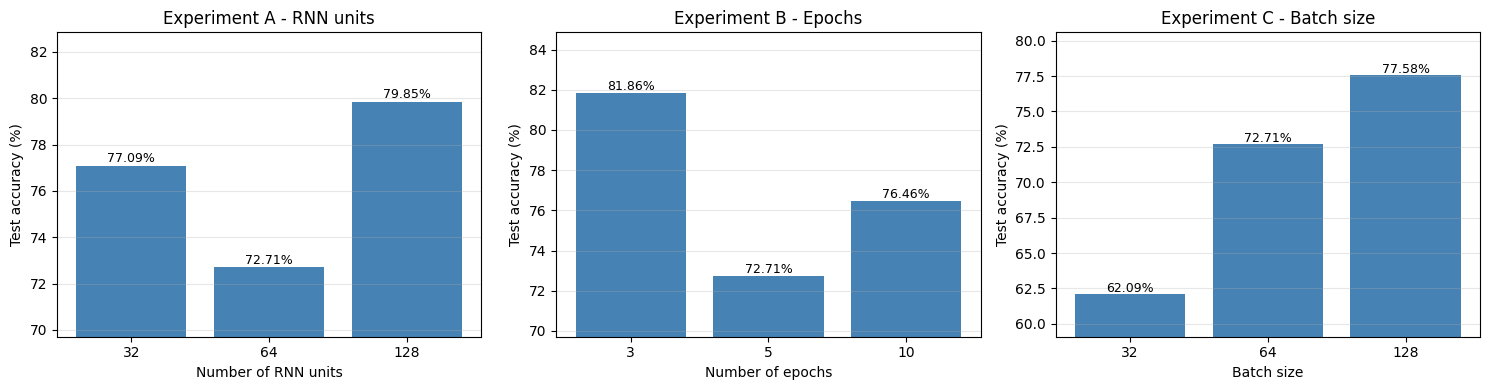

In [18]:
# ---- Visual comparison of the three experiments ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
groups = [("Experiment A - RNN units",  ["A1", "A2", "A3"], ["32", "64", "128"],  "Number of RNN units"),
          ("Experiment B - Epochs",     ["B1", "B2", "B3"], ["3", "5", "10"],     "Number of epochs"),
          ("Experiment C - Batch size", ["C1", "C2", "C3"], ["32", "64", "128"],  "Batch size")]
for ax, (title, ids, labels, xlabel) in zip(axes, groups):
    vals = [results_df.loc[results_df["Experiment"] == i, "Test Accuracy"].iloc[0] * 100 for i in ids]
    ax.bar(labels, vals, color="steelblue")
    for x, v in zip(labels, vals):
        ax.text(x, v + 0.15, f"{v:.2f}%", ha="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_ylim(min(vals) - 3, max(vals) + 3)
    ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Analysis of the experiments
Generated from the table above. **Important caveat:** each configuration was trained once with one seed. SimpleRNN training is noisy, so differences of roughly 1-2 percentage points can be random variation rather than a real effect of the hyperparameter.

In [19]:
def pp(a, b):
    """Difference a - b in percentage points."""
    return (a - b) * 100

def effect(delta_pp, noise_pp=1.0):
    return "improved" if delta_pp > noise_pp else ("reduced" if delta_pp < -noise_pp else "made little difference to")

gap = lambda r: (r["train_acc"] - r["val_acc"]) * 100
lines = []

# --- A: units ---
d = pp(res_A3["test_acc"], res_A1["test_acc"])
lines.append(f"- **Experiment A (RNN units):** going from 32 to 128 units {effect(d)} test accuracy "
             f"({res_A1['test_acc']:.2%} -> {res_A3['test_acc']:.2%}, {d:+.2f} pp). Model size grew from {res_A1['params']:,} to {res_A3['params']:,} "
             f"parameters and training time from {res_A1['time_s']:.0f} s to {res_A3['time_s']:.0f} s. "
             f"Train-validation gap: {gap(res_A1):.1f} pp (32 units) vs {gap(res_A3):.1f} pp (128 units).")

# --- B: epochs ---
d = pp(res_B3["test_acc"], res_B1["test_acc"])
trend = "widened, a sign of overfitting" if gap(res_B3) > gap(res_B1) + 2 else "did not widen markedly"
lines.append(f"- **Experiment B (epochs):** training for 10 instead of 3 epochs {effect(d)} test accuracy "
             f"({res_B1['test_acc']:.2%} -> {res_B3['test_acc']:.2%}, {d:+.2f} pp). Training accuracy rose from {res_B1['train_acc']:.2%} to {res_B3['train_acc']:.2%}, "
             f"validation accuracy went from {res_B1['val_acc']:.2%} to {res_B3['val_acc']:.2%}, and the train-validation gap {trend} ({gap(res_B1):.1f} pp -> {gap(res_B3):.1f} pp).")

# --- C: batch size ---
d = pp(res_C1["test_acc"], res_C3["test_acc"])
n_fit = int(len(x_train) * 0.8)
steps = lambda b: int(np.ceil(n_fit / b))
lines.append(f"- **Experiment C (batch size):** batch 32 versus batch 128 {effect(d)} test accuracy ({res_C1['test_acc']:.2%} vs {res_C3['test_acc']:.2%}, {d:+.2f} pp; positive means the smaller batch was better). "
             f"A batch of 32 makes {steps(32):,} weight updates per epoch against {steps(128):,} for batch 128, so it usually learns more per epoch but each epoch is slower "
             f"(training time {res_C1['time_s']:.0f} s vs {res_C3['time_s']:.0f} s) and its gradient estimates are noisier.")

# --- overall ---
best_id, best_param, best_res = max(experiment_table, key=lambda row: row[2]["test_acc"])
accs = [r["test_acc"] for _, _, r in experiment_table]
lines.append(f"- **Best configuration overall:** {best_id} ({best_param}) with {best_res['test_acc']:.2%} test accuracy; the spread across all nine runs is {(max(accs) - min(accs)) * 100:.2f} pp.")
if (max(accs) - min(accs)) * 100 < 2:
    lines.append("- Because the whole spread is small, no single hyperparameter has a decisive effect here; the architecture (a SimpleRNN) is the main limiting factor, not the settings.")

# A SimpleRNN occasionally fails to train at all - flag such runs instead of reading a trend into them
failed = [e for e, _, r in experiment_table if r["test_acc"] < 0.60]
if failed:
    lines.append(f"- **Warning:** {', '.join(failed)} ended near chance level (below 60% test accuracy). A SimpleRNN can fail to train (exploding/vanishing gradients) "
                 "or memorise the training set, so this reflects the instability of the architecture rather than a real hyperparameter trend. "
                 "Typical fixes: re-run with another SEED, add gradient clipping (`tf.keras.optimizers.Adam(clipnorm=1.0)`), or switch to LSTM/GRU.")
display(Markdown("\n".join(lines)))

- **Experiment A (RNN units):** going from 32 to 128 units improved test accuracy (77.09% -> 79.85%, +2.76 pp). Model size grew from 1,285,185 to 1,313,025 parameters and training time from 32 s to 33 s. Train-validation gap: 22.6 pp (32 units) vs 9.7 pp (128 units).
- **Experiment B (epochs):** training for 10 instead of 3 epochs reduced test accuracy (81.86% -> 76.46%, -5.40 pp). Training accuracy rose from 91.62% to 99.87%, validation accuracy went from 82.74% to 77.74%, and the train-validation gap widened, a sign of overfitting (8.9 pp -> 22.1 pp).
- **Experiment C (batch size):** batch 32 versus batch 128 reduced test accuracy (62.09% vs 77.58%, -15.50 pp; positive means the smaller batch was better). A batch of 32 makes 625 weight updates per epoch against 157 for batch 128, so it usually learns more per epoch but each epoch is slower (training time 56 s vs 19 s) and its gradient estimates are noisier.
- **Best configuration overall:** B1 (Epochs = 3) with 81.86% test accuracy; the spread across all nine runs is 19.77 pp.

---
## Task 8 - Text Prediction

`predict_sentiment()` turns raw text into the same format the model was trained on: lower-case -> split into words -> map each word to its IMDB index (+3 offset, unknown / out-of-vocabulary words -> index 2) -> prepend the start token (1) -> pad to length 200 -> predict. The model outputs P(Positive); a value >= 0.5 is labelled **Positive**.

In [20]:
def encode_review(text):
    """Convert a raw review string into a padded integer sequence the model can read."""
    words = re.sub(r"[^a-z0-9' ]", " ", text.lower()).split()
    seq = [1]                                              # <START> token, as in the training data
    for w in words:
        idx = word_index.get(w)
        seq.append(idx + 3 if (idx is not None and idx + 3 < VOCAB_SIZE) else 2)   # 2 = unknown word
    return pad_sequences([seq], maxlen=MAX_LEN)

def predict_sentiment(text, model=baseline_model):
    """Return ('Positive' | 'Negative', probability of Positive)."""
    prob = float(model.predict(encode_review(text), verbose=0)[0][0])
    return ("Positive" if prob >= 0.5 else "Negative"), prob

In [21]:
# ---- Five new reviews written for this lab ----
new_reviews = [
    ("Review 1", "Positive", "This movie was absolutely wonderful. The acting was brilliant, the story was touching and I loved every minute of it. Highly recommended!"),
    ("Review 2", "Negative", "Terrible film. The plot was boring and predictable, the acting was awful, and I regret wasting two hours of my life on it."),
    ("Review 3", "Positive", "A fantastic and moving drama with great performances and a beautiful soundtrack. One of the best films I have seen this year."),
    ("Review 4", "Negative", "I could not wait for this movie to end. The dialogue was painful, the characters were dull and the ending made no sense at all."),
    ("Review 5", "Positive", "Funny, clever and full of heart. The cast has great chemistry and the script is excellent. I would happily watch it again."),
]

rows = []
raw_probs = {}
for name, expected, text in new_reviews:
    predicted, prob = predict_sentiment(text)
    raw_probs[name] = prob
    rows.append({"Review": name, "Actual/Expected Sentiment": expected, "Predicted Sentiment": predicted,
                 "Probability (P(Positive))": f"{prob:.4f}", "Correct?": "Yes" if predicted == expected else "No"})
    print(f"{name} [{expected}]: {text}")

print()
pred_df = pd.DataFrame(rows)
display(pred_df)

n_correct = int((pred_df["Correct?"] == "Yes").sum())
print(f"\nThe model classified {n_correct} of {len(pred_df)} new reviews correctly.")

Review 1 [Positive]: This movie was absolutely wonderful. The acting was brilliant, the story was touching and I loved every minute of it. Highly recommended!
Review 2 [Negative]: Terrible film. The plot was boring and predictable, the acting was awful, and I regret wasting two hours of my life on it.
Review 3 [Positive]: A fantastic and moving drama with great performances and a beautiful soundtrack. One of the best films I have seen this year.
Review 4 [Negative]: I could not wait for this movie to end. The dialogue was painful, the characters were dull and the ending made no sense at all.
Review 5 [Positive]: Funny, clever and full of heart. The cast has great chemistry and the script is excellent. I would happily watch it again.



,Review,Actual/Expected Sentiment,Predicted Sentiment,Probability (P(Positive)),Correct?
0,Review 1,Positive,Positive,1.0000,Yes
1,Review 2,Negative,Negative,0.0119,Yes
2,Review 3,Positive,Positive,0.9982,Yes
3,Review 4,Negative,Negative,0.0022,Yes
4,Review 5,Positive,Positive,0.9992,Yes



The model classified 5 of 5 new reviews correctly.


In [22]:
wrong = pred_df[pred_df["Correct?"] == "No"]["Review"].tolist()
if not wrong:
    msg = ("All five reviews were classified correctly. They use strong, unambiguous sentiment words (e.g. *wonderful, brilliant, terrible, awful, boring*), "
           "which the embedding layer has learned to associate with one class. Five reviews is a very small sample, so this is encouraging but not a proof of accuracy.")
else:
    confident = [w for w in wrong if abs(raw_probs[w] - 0.5) > 0.15]     # far from the 0.5 threshold
    certainty = ("Their probabilities lie close to 0.5, so the model was genuinely unsure about them." if not confident else
                 f"{', '.join(confident)} {'was' if len(confident) == 1 else 'were'} misclassified with high confidence (probability far from 0.5), "
                 "which suggests the model relies on a few strong words or has not learned the sentiment well enough yet.")
    msg = (f"The model misclassified {', '.join(wrong)}. Likely reasons: a SimpleRNN keeps only a short-term memory, so words early in the review fade by the end; "
           f"negations and mixed wording are hard for it; and words outside the 10,000-word vocabulary become 'unknown'. {certainty} "
           "Five reviews is a very small sample, so compare with the test accuracy for the overall picture.")
display(Markdown("**Observation:** " + msg))

**Observation:** All five reviews were classified correctly. They use strong, unambiguous sentiment words (e.g. *wonderful, brilliant, terrible, awful, boring*), which the embedding layer has learned to associate with one class. Five reviews is a very small sample, so this is encouraging but not a proof of accuracy.

---
## Task 9 - Challenge Activity: Two-Layer RNN and `return_sequences=True`

### What does `return_sequences=True` do?
A `SimpleRNN` processes 200 time steps and produces a hidden state at **each** step. By default (`return_sequences=False`) it returns only the **last** hidden state - one vector per review, shape `(batch, units)`. With `return_sequences=True` it returns the hidden state of **every** step - shape `(batch, 200, units)`. A second RNN layer expects a *sequence* as input, so the first layer must output the full sequence. The cell below demonstrates the shapes and shows the error you get if it is left out.

In [23]:
# ---- Demonstrate the shapes with a fake batch of 2 embedded reviews ----
demo_input = tf.random.normal((2, MAX_LEN, EMBED_DIM))      # (batch, time steps, embedding size)
print("Input to the RNN                         :", demo_input.shape)
print("SimpleRNN(64)                            ->", layers.SimpleRNN(64)(demo_input).shape, "  (only the last hidden state)")
print("SimpleRNN(64, return_sequences=True)     ->", layers.SimpleRNN(64, return_sequences=True)(demo_input).shape, " (a hidden state for every time step)")

# ---- What happens if we stack two SimpleRNN layers WITHOUT return_sequences=True? ----
try:
    models.Sequential([layers.Input(shape=(MAX_LEN,)),
                       layers.Embedding(VOCAB_SIZE, EMBED_DIM),
                       layers.SimpleRNN(64),                       # returns 2-D output ...
                       layers.SimpleRNN(64),                       # ... but this layer needs 3-D input
                       layers.Dense(1, activation="sigmoid")])
    print("\nNo error was raised at build time in this Keras version.")
except Exception as e:
    print("\nStacking without return_sequences=True fails:")
    print(f"  {type(e).__name__}: {str(e)[:220]}")

Input to the RNN                         : (2, 200, 128)
SimpleRNN(64)                            -> (2, 64)   (only the last hidden state)
SimpleRNN(64, return_sequences=True)     -> (2, 200, 64)  (a hidden state for every time step)

Stacking without return_sequences=True fails:
  ValueError: Input 0 with name 'None' of layer 'simple_rnn_10' is incompatible with the layer: expected ndim=3, found ndim=2. Full shape received: (None, 64)


In [24]:
# ---- Two-layer model: Embedding -> SimpleRNN(64, return_sequences=True) -> SimpleRNN(64) -> Dense ----
tf.keras.utils.set_random_seed(SEED)
build_rnn(units=64, two_layer=True).summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_11 (SimpleRNN)       │ (None, 200, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_12 (SimpleRNN)       │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,300,673 (4.96 MB)

 Trainable params: 1,300,673 (4.96 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Both models are trained through the same function so that accuracy AND training time are
# measured under identical conditions (the very first training run also pays a one-off warm-up cost).
print("Training single-layer RNN ...")
single_result = run_experiment(units=64, epochs=5, batch_size=64, two_layer=False)
print(f"  done -> test accuracy {single_result['test_acc']:.4f} ({single_result['time_s']:.0f} s)")

print("Training two-layer RNN ...")
two_result = run_experiment(units=64, epochs=5, batch_size=64, two_layer=True)
print(f"  done -> test accuracy {two_result['test_acc']:.4f} ({two_result['time_s']:.0f} s)")

comparison = pd.DataFrame([
    {"Model": "Single-layer RNN (64)", "Training Accuracy": single_result["train_acc"], "Validation Accuracy": single_result["val_acc"],
     "Test Accuracy": single_result["test_acc"], "Training Time (s)": single_result["time_s"], "Trainable Parameters": single_result["params"]},
    {"Model": "Two-layer RNN (64 + 64)", "Training Accuracy": two_result["train_acc"], "Validation Accuracy": two_result["val_acc"],
     "Test Accuracy": two_result["test_acc"], "Training Time (s)": two_result["time_s"], "Trainable Parameters": two_result["params"]}])
shown = comparison.copy()
for col in ["Training Accuracy", "Validation Accuracy", "Test Accuracy"]:
    shown[col] = shown[col].map(lambda v: f"{v:.2%}")
shown["Training Time (s)"] = shown["Training Time (s)"].map(lambda v: f"{v:.0f}")
shown["Trainable Parameters"] = shown["Trainable Parameters"].map(lambda v: f"{v:,}")
display(shown)

Training single-layer RNN ...
  done -> test accuracy 0.6771 (31 s)
Training two-layer RNN ...
  done -> test accuracy 0.7282 (54 s)


,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Training Time (s),Trainable Parameters
0,Single-layer RNN (64),96.80%,68.24%,67.71%,31,"1,292,417"
1,Two-layer RNN (64 + 64),94.52%,72.34%,72.82%,54,"1,300,673"


In [26]:
# ---- Answers to the four challenge questions (generated from the results above) ----
d = pp(two_result["test_acc"], single_result["test_acc"])
ratio = two_result["time_s"] / single_result["time_s"]
better = "two-layer" if d > 0.3 else ("single-layer" if d < -0.3 else "neither clearly")
slower = "two-layer" if ratio > 1.05 else ("single-layer" if ratio < 0.95 else "neither clearly")

answers = [
    f"**1. Which model gives better test accuracy?** {single_result['test_acc']:.2%} (single-layer) vs {two_result['test_acc']:.2%} (two-layer), a difference of {d:+.2f} pp: "
    + ("the two-layer model is better." if better == "two-layer" else "the single-layer model is better." if better == "single-layer" else "the two models are essentially tied; the gap is within run-to-run noise."),
    f"**2. Which model takes longer to train?** The {slower} model: {single_result['time_s']:.0f} s vs {two_result['time_s']:.0f} s (ratio {ratio:.2f}x). "
    "The second recurrent layer adds a second pass over all 200 time steps, and RNN steps cannot be parallelised across time, so training cost grows roughly with the number of recurrent layers.",
    "**3. Does adding another RNN layer always improve performance?** **No.** A deeper stack adds capacity and more parameters, but it also makes gradients travel through even more "
    "operations, which worsens the vanishing-gradient problem of SimpleRNNs, increases training time and the risk of overfitting, and needs more data and tuning to pay off. "
    + ("In this experiment it did not give a clear gain." if better != "two-layer" else "In this experiment it helped, but the gain should be checked with several seeds before being trusted."),
    "**4. Purpose of `return_sequences=True`:** it makes the first RNN layer output its hidden state for **every** time step (shape `(batch, 200, units)`) instead of only the last one, "
    "so that the second RNN layer receives the sequence it needs. Without it the second layer gets a 2-D tensor and Keras raises the shape error shown above."]
display(Markdown("\n\n".join(answers)))

**1. Which model gives better test accuracy?** 67.71% (single-layer) vs 72.82% (two-layer), a difference of +5.11 pp: the two-layer model is better.

**2. Which model takes longer to train?** The two-layer model: 31 s vs 54 s (ratio 1.75x). The second recurrent layer adds a second pass over all 200 time steps, and RNN steps cannot be parallelised across time, so training cost grows roughly with the number of recurrent layers.

**3. Does adding another RNN layer always improve performance?** **No.** A deeper stack adds capacity and more parameters, but it also makes gradients travel through even more operations, which worsens the vanishing-gradient problem of SimpleRNNs, increases training time and the risk of overfitting, and needs more data and tuning to pay off. In this experiment it helped, but the gain should be checked with several seeds before being trusted.

**4. Purpose of `return_sequences=True`:** it makes the first RNN layer output its hidden state for **every** time step (shape `(batch, 200, units)`) instead of only the last one, so that the second RNN layer receives the sequence it needs. Without it the second layer gets a 2-D tensor and Keras raises the shape error shown above.

---
## Discussion Questions

**1. What is an RNN and why is it suitable for text classification?**
A Recurrent Neural Network processes a sequence one element at a time while carrying a **hidden state** from one step to the next: `h_t = tanh(W_x x_t + W_h h_(t-1) + b)`. The same weights are reused at every step, so it can handle reviews of any length with a fixed number of parameters, and the hidden state acts as a running summary (memory) of the words read so far. Text is an ordered sequence in which meaning depends on context ("not good" differs from "good"), which is exactly what an ordinary feed-forward network ignores.

**2. What is the purpose of the Embedding layer?**
It is a trainable lookup table that maps each integer word index to a dense vector (here 128 numbers). Compared with one-hot vectors (10,000 mostly-zero dimensions), embeddings are compact and let words with similar sentiment or meaning end up with similar vectors. The vectors are learned together with the rest of the network, so they adapt to the sentiment task. Here it holds 10,000 x 128 = 1.28 million parameters.

**3. Why is padding required?**
Neural-network batches are rectangular tensors, but reviews have different lengths. Shorter reviews are padded with zeros and longer ones truncated so every review has exactly 200 tokens. Pre-padding is used so the real words come last, right before the final hidden state is read. (Padding zeros can additionally be ignored with `mask_zero=True`; this lab does not use it.)

**4. Why is sigmoid activation used in the output layer?**
Sigmoid squashes any real number into the range (0, 1), which can be read as the probability that a review is positive. A threshold of 0.5 then gives the class. It is smooth and differentiable, so gradients can flow, and it is the natural output pairing for binary cross-entropy.

**5. Why is binary cross-entropy used as the loss function?**
For a binary target the correct probabilistic loss is `-[y log(p) + (1-y) log(1-p)]` (the negative log-likelihood of a Bernoulli variable). It punishes confident wrong predictions very heavily, and combined with a sigmoid output its gradient with respect to the pre-activation simplifies to `(p - y)`, so learning does not stall the way it can with mean squared error.

**6. What is the vanishing-gradient problem?**
During back-propagation through time, the gradient reaching an early time step is a product of many factors (derivatives of tanh, which are at most 1, and the recurrent weight matrix). Over 200 steps this product shrinks exponentially towards zero, so the early part of the review receives almost no learning signal and the network can only learn short-range dependencies. The opposite case, gradients growing exponentially, is the exploding-gradient problem. LSTM/GRU cells, gradient clipping and shorter sequences are the usual remedies.

**7. What happens when the number of RNN units is increased?**
The hidden state becomes larger, so the layer can store more information and learn more complex patterns, but the parameter count grows (`units x (input_dim + units + 1)`, i.e. roughly quadratically in the units), training becomes slower and overfitting becomes more likely. Gains diminish, and extra units do not cure the vanishing-gradient problem. The observed effect in this lab is printed below.

**8. What is overfitting?**
Overfitting happens when a model learns the training data too closely - including its noise - and therefore performs much worse on unseen data. Signs: training accuracy keeps rising while validation accuracy stalls or falls, and validation loss increases while training loss keeps decreasing.

**9. How can overfitting be reduced in an RNN?**
(a) Dropout between layers and `recurrent_dropout` inside the RNN, (b) early stopping on validation loss, (c) fewer units or a smaller embedding, (d) L2 weight regularisation, (e) more training data or data augmentation, (f) pretrained embeddings (e.g. GloVe), and (g) training for fewer epochs.

**10. What is the difference between SimpleRNN, LSTM and GRU?**

| | SimpleRNN | LSTM | GRU |
|---|---|---|---|
| Memory | one hidden state | hidden state + separate **cell state** | one hidden state |
| Gates | none | input, forget, output | update, reset |
| Parameters (relative) | 1x | about 4x | about 3x |
| Long-range dependencies | poor (vanishing gradients) | very good | good |
| Speed | fastest | slowest | between the two |

LSTM and GRU use gates to decide what to keep, add or forget, which lets gradients flow across many steps; GRU is a lighter simplification of LSTM that often performs similarly.

In [27]:
# ---- Observed effect of the number of RNN units (supports the answer to question 7) ----
print(f"{'Units':>6} | {'Parameters':>10} | {'Training acc':>12} | {'Validation acc':>14} | {'Test acc':>8} | {'Time (s)':>8}")
for units, r in [(32, res_A1), (64, res_A2), (128, res_A3)]:
    print(f"{units:>6} | {r['params']:>10,} | {r['train_acc']:>12.2%} | {r['val_acc']:>14.2%} | {r['test_acc']:>8.2%} | {r['time_s']:>8.0f}")

 Units | Parameters | Training acc | Validation acc | Test acc | Time (s)
    32 |  1,285,185 |       98.91% |         76.34% |   77.09% |       32
    64 |  1,292,417 |       98.61% |         71.56% |   72.71% |       33
   128 |  1,313,025 |       89.25% |         79.50% |   79.85% |       33


---
## Final Conclusion

In [28]:
# ---- Build the conclusion from the experimental results ----
d_units  = pp(res_A3["test_acc"], res_A1["test_acc"])
d_epochs = pp(res_B3["test_acc"], res_B1["test_acc"])
d_two    = pp(two_result["test_acc"], single_result["test_acc"])

units_s = ("Increasing the units from 32 to 128 improved accuracy" if d_units > 1 else
           "Increasing the units from 32 to 128 did not help" if d_units < -1 else
           "Changing the units from 32 to 128 made little difference") + f" ({d_units:+.2f} pp)" +           (" while making training slower." if res_A3["time_s"] > res_A1["time_s"] else ".")
epochs_s = ("Training for 10 epochs instead of 3 improved accuracy" if d_epochs > 1 else
            "Training for 10 epochs instead of 3 did not help" if d_epochs < -1 else
            "Training for 10 epochs instead of 3 changed little") + f" ({d_epochs:+.2f} pp)."
two_s = ("The two-layer RNN was better" if d_two > 0.3 else "The two-layer RNN was not better" if d_two < -0.3 else "The two-layer RNN performed about the same") + \
        f" ({two_result['test_acc']:.2%} vs {single_result['test_acc']:.2%}) and trained {two_result['time_s'] / single_result['time_s']:.1f}x as long."
over_s = ("A visible train-validation gap shows overfitting, which dropout or early stopping could reduce." if gap(baseline_result) > 3
          else "The small train-validation gap suggests little overfitting at 5 epochs.")

conclusion = (f"In this lab I built a SimpleRNN sentiment classifier for IMDB reviews with an Embedding layer, a recurrent layer and a sigmoid output. "
              f"The baseline (64 units, 5 epochs, batch 64) reached {test_acc:.2%} test accuracy. The best test accuracy among the experiments was "
              f"{best_res['test_acc']:.2%} with {best_id} ({best_param}). {units_s} {epochs_s} {two_s} {over_s} "
              "The main limitations are noisy SimpleRNN training, differences of a point or two that may be random, and the vanishing-gradient problem, which makes it hard "
              "to remember information from the start of a 200-token review. LSTM or GRU layers should improve the system because their gates let information and gradients "
              "flow across many time steps, and they could be combined with dropout and pretrained embeddings for further gains.")

print(f"[{len(conclusion.split())} words]\n")
display(Markdown(conclusion))

[170 words]



In this lab I built a SimpleRNN sentiment classifier for IMDB reviews with an Embedding layer, a recurrent layer and a sigmoid output. The baseline (64 units, 5 epochs, batch 64) reached 72.71% test accuracy. The best test accuracy among the experiments was 81.86% with B1 (Epochs = 3). Increasing the units from 32 to 128 improved accuracy (+2.76 pp) while making training slower. Training for 10 epochs instead of 3 did not help (-5.40 pp). The two-layer RNN was better (72.82% vs 67.71%) and trained 1.7x as long. A visible train-validation gap shows overfitting, which dropout or early stopping could reduce. The main limitations are noisy SimpleRNN training, differences of a point or two that may be random, and the vanishing-gradient problem, which makes it hard to remember information from the start of a 200-token review. LSTM or GRU layers should improve the system because their gates let information and gradients flow across many time steps, and they could be combined with dropout and pretrained embeddings for further gains.

---
## Appendix - Viva Preparation (short answers)

1. **ANN vs RNN?** An ANN (feed-forward) maps a fixed-size input to an output in one pass with no memory; an RNN reads sequences step by step and feeds its hidden state back into itself.
2. **Why does an RNN have memory?** Because the hidden state from step *t-1* is an input to step *t*, so information about earlier elements persists.
3. **What is a hidden state?** The vector `h_t` the RNN keeps after each step - a compressed summary of everything read so far.
4. **Role of the Embedding layer?** Converts word indices into dense, learnable vectors that capture word meaning.
5. **What is sequence padding?** Adding zeros (or truncating) so all sequences have the same length and can be batched.
6. **Explain `return_sequences=True`.** The RNN returns the hidden state of every time step instead of only the last; needed before stacking another RNN layer.
7. **Vanishing-gradient problem?** Gradients shrink exponentially when back-propagated through many time steps, so early inputs are not learned from.
8. **Why is LSTM preferred for long sequences?** Its cell state and gates (input/forget/output) let information and gradients pass across many steps with little decay.
9. **What is binary cross-entropy?** The loss `-[y log p + (1-y) log(1-p)]` for two-class problems; it heavily penalises confident wrong predictions.
10. **What if the learning rate is too high?** Updates overshoot: the loss oscillates or diverges (RNNs may show exploding gradients); too low a rate makes training very slow.
11. **What is overfitting?** Fitting training data (and its noise) too well so that performance on unseen data is poor.
12. **How can dropout be used in an RNN?** `layers.Dropout` between layers, or `SimpleRNN(units, dropout=0.2, recurrent_dropout=0.2)` for the inputs and the recurrent connections.
13. **LSTM vs GRU?** LSTM has three gates and a separate cell state (more parameters); GRU has two gates and no cell state (faster, fewer parameters); accuracy is usually similar.
14. **Why sigmoid for binary classification?** It outputs a value in (0, 1) that is interpreted as the probability of the positive class and pairs naturally with binary cross-entropy.
15. **Does more RNN units always improve accuracy?** No - gains diminish, training gets slower, overfitting rises, and the vanishing-gradient limitation remains (see Experiment A).

